# Smart Credit risk Scoring System 

### Project Purpose and Key Questions : 
> This project aims to develop a credit risk scoring system to help lenders identify potential loan defaults and make smarter lending decisions.
**Key Questions for Exploratory Data Analysis (EDA) and Modelling :**
> 1. Which borrower characteristics are associated with increased default risk
> 2. What features are the strongest predictors of loan default?
> 3. How can lenders effectively predict and mitigate credit risk when issuing loans?
> 4. What specific risks should lenders consider when issuing loans to different borrower types?
> 5. What are the correlations and relationships among key features affecting lending risk?

In [1]:
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_selection import VarianceThreshold
import xgboost as xgb

In [2]:
df = pd.read_csv("../data/accepted_2007_to_2018Q4.csv", engine="pyarrow")

In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2260701 entries, 0 to 2260700
Columns: 151 entries, id to settlement_term
dtypes: float64(113), object(38)
memory usage: 2.5+ GB


,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,fico_range_low,...,deferral_term,hardship_amount,hardship_length,hardship_dpd,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,settlement_amount,settlement_percentage,settlement_term
count,0.0,2.260668e+06,2.260668e+06,2.260668e+06,2.260668e+06,2.260668e+06,2.260664e+06,2.258957e+06,2.260639e+06,2.260668e+06,...,10917.0,10917.000000,10917.0,10917.000000,8651.000000,10917.000000,10917.000000,34246.000000,34246.000000,34246.000000
mean,NaN,1.504693e+04,1.504166e+04,1.502344e+04,1.309283e+01,4.458068e+02,7.799243e+04,1.882420e+01,3.068792e-01,6.985882e+02,...,3.0,155.045981,3.0,13.743886,454.798089,11636.883942,193.994321,5010.664267,47.780365,13.191322
std,NaN,9.190245e+03,9.188413e+03,9.192332e+03,4.832138e+00,2.671735e+02,1.126962e+05,1.418333e+01,8.672303e-01,3.301038e+01,...,0.0,129.040594,0.0,9.671178,375.385500,7625.988281,198.629496,3693.122590,7.311822,8.159980
min,NaN,5.000000e+02,5.000000e+02,0.000000e+00,5.310000e+00,4.930000e+00,0.000000e+00,-1.000000e+00,0.000000e+00,6.100000e+02,...,3.0,0.640000,3.0,0.000000,1.920000,55.730000,0.010000,44.210000,0.200000,0.000000
25%,NaN,8.000000e+03,8.000000e+03,8.000000e+03,9.490000e+00,2.516500e+02,4.600000e+04,1.189000e+01,0.000000e+00,6.750000e+02,...,3.0,59.440000,3.0,5.000000,175.230000,5627.000000,44.440000,2208.000000,45.000000,6.000000
50%,NaN,1.290000e+04,1.287500e+04,1.280000e+04,1.262000e+01,3.779900e+02,6.500000e+04,1.784000e+01,0.000000e+00,6.900000e+02,...,3.0,119.140000,3.0,15.000000,352.770000,10028.390000,133.160000,4146.110000,45.000000,14.000000
75%,NaN,2.000000e+04,2.000000e+04,2.000000e+04,1.599000e+01,5.933200e+02,9.300000e+04,2.449000e+01,0.000000e+00,7.150000e+02,...,3.0,213.260000,3.0,22.000000,620.175000,16151.890000,284.190000,6850.172500,50.000000,18.000000
max,NaN,4.000000e+04,4.000000e+04,4.000000e+04,3.099000e+01,1.719830e+03,1.100000e+08,9.990000e+02,5.800000e+01,8.450000e+02,...,3.0,943.940000,3.0,37.000000,2680.890000,40306.410000,1407.860000,33601.000000,521.350000,181.000000


In [4]:
df['loan_status'].value_counts()

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64

## Data Cleaning & Preprocessing

The raw data has 2.26 million loans and 151 columns, so there was a lot to clean.

- I only kept loans that were finished (either fully paid or defaulted), and made a yes/no "default" column as the target.
- I dropped columns with more than 40% missing values, since filling in that much would mostly be guessing.
- I also dropped columns that would "leak" the answer, like payments received after the loan started. The model wouldn't know these when the loan is approved, so using them would be cheating.
- I turned loan term and employment length into numbers, and created new columns like issue year and credit age.

In [5]:
to_drop = [
    'funded_amnt_inv', 'out_prncp', 'out_prncp_inv',
    'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
    'total_rec_int', 'total_rec_late_fee', 'recoveries',
    'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
    'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low',
    'policy_code', 'hardship_flag', 'debt_settlement_flag', 'total_pymnt',
    'id', 'emp_title', 'url', 'title', 'zip_code', 'pymnt_plan', 'inq_last_6mths', 'inq_last_12m'
]

df_cleaned = df.drop(columns = [col for col in to_drop if col in df.columns])
df_cleaned = df_cleaned.dropna(how='all')

#we can see from df.describe() theres is a negative value in dti, logically dti can not be negative, so drop rows with negative dti
df_cleaned = df_cleaned[df_cleaned['dti'] >= 0] 

df_cleaned['term'] = df_cleaned['term'].str.extract(r'(\d+)').astype(int)
df_cleaned = df_cleaned.rename(columns ={'term' : 'term (months)'})
df_cleaned['emp_length']= (
    df_cleaned['emp_length']
    .replace('< 1 year', '0')                 
    .str.extract(r'(\d+)')                    
    .astype(float)                             
)

In [6]:
# Extract and convert datetime columns 
df_cleaned['issue_d'] = pd.to_datetime(df_cleaned['issue_d'], format='%b-%Y')
df_cleaned['issue_year'] = df_cleaned['issue_d'].dt.year
df_cleaned['issue_month'] = df_cleaned['issue_d'].dt.month
df_cleaned.drop(columns=['issue_d'], inplace=True)

df_cleaned['earliest_cr_line'] = pd.to_datetime(df_cleaned['earliest_cr_line'], format='%b-%Y')
df_cleaned['credit_age (months)'] = (df_cleaned['issue_year'] * 12 + df_cleaned['issue_month']) - (df_cleaned['earliest_cr_line'].dt.year * 12 + df_cleaned['earliest_cr_line'].dt.month)
df_cleaned.drop(columns=['earliest_cr_line'], inplace=True)

df_cleaned.drop(columns=['grade'], inplace=True)

In [7]:
# Change 'loan_status' to binary in order to provide a clear target (yes/no) for modelling use
default_status = ['Charged Off', 'Default', 'Late (31-120 days)', 'Late (16-30 days)', 'Does not meet the credit policy. Status:Charged Off'
]
fully_paid = ['Fully Paid', 'Does not meet the credit policy. Status:Fully Paid']
df_cleaned = df_cleaned[df_cleaned['loan_status'].isin(default_status + fully_paid)]

df_cleaned['target_default'] = df_cleaned['loan_status'].apply(lambda x: 1 if x in default_status else 0)

df_cleaned = df_cleaned.drop(columns=['loan_status']) 

In [8]:
#drop with missing >40% 
missing = df_cleaned.isnull().mean().sort_values(ascending=False)
missing_cols = missing[missing > 0.4].index.tolist()
df_cleaned = df_cleaned.drop(columns = missing_cols)

In [9]:
#impute rows with missing value <20%
missing_percent = df_cleaned.isnull().mean() * 100
cols_less_20 = missing_percent[missing_percent < 20].index

#for numerical columns, impute with median value
numerical_cols = df_cleaned[cols_less_20].select_dtypes(include=['number']).columns
for col in numerical_cols:
    median_val = df_cleaned[col].median()
    df_cleaned[col] = df_cleaned[col].fillna(median_val)

#for categorical, impute with mode value
categorical_cols = df_cleaned[cols_less_20].select_dtypes(include=['object', 'category']).columns
cols_mode = [
    'sub_grade',
    'home_ownership',
    'verification_status',
    'initial_list_status',
    'application_type',
    'disbursement_method'
]

for col in cols_mode:
    mode_val = df_cleaned[col].mode()[0]
    df_cleaned[col] = df_cleaned[col].fillna(mode_val)

#not all columns can be imputed with mode 
df_cleaned['purpose'] = df_cleaned['purpose'].fillna('Unknown')
df_cleaned['addr_state'] = df_cleaned['addr_state'].fillna('Unknown')

## One Hot Encoding

In [10]:
df_cleaned.select_dtypes(include=['object']).columns.tolist() #identify variable object dtype for one hot encoding 

['sub_grade',
 'home_ownership',
 'verification_status',
 'purpose',
 'addr_state',
 'initial_list_status',
 'application_type',
 'disbursement_method']

In [11]:
cat_cols = [
 'home_ownership',
 'verification_status',
 'purpose',
 'addr_state',
 'initial_list_status',
 'application_type',
 'disbursement_method'
]

df_cleaned = pd.get_dummies(df_cleaned, columns = cat_cols, drop_first = True) #one hot encoding using pd.get_dummies()
df_cleaned

,loan_amnt,funded_amnt,term (months),int_rate,installment,sub_grade,emp_length,annual_inc,dti,delinq_2yrs,...,addr_state_UT,addr_state_VA,addr_state_VT,addr_state_WA,addr_state_WI,addr_state_WV,addr_state_WY,initial_list_status_w,application_type_Joint App,disbursement_method_DirectPay
0,3600.0,3600.0,36,13.99,123.03,C4,10.0,55000.0,5.91,0.0,...,False,False,False,False,False,False,False,True,False,False
1,24700.0,24700.0,36,11.99,820.28,C1,10.0,65000.0,16.06,1.0,...,False,False,False,False,False,False,False,True,False,False
2,20000.0,20000.0,60,10.78,432.66,B4,10.0,63000.0,10.78,0.0,...,False,False,False,False,False,False,False,True,True,False
4,10400.0,10400.0,60,22.45,289.91,F1,3.0,104433.0,25.37,1.0,...,False,False,False,False,False,False,False,True,False,False
5,11950.0,11950.0,36,13.44,405.18,C3,4.0,34000.0,10.20,0.0,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2260688,18000.0,18000.0,60,9.49,377.95,B2,5.0,130000.0,20.59,0.0,...,False,False,False,False,False,False,False,False,False,False
2260690,29400.0,29400.0,60,13.99,683.94,C3,9.0,180792.0,22.03,0.0,...,False,False,False,False,False,False,False,False,False,False
2260691,32000.0,32000.0,60,14.49,752.74,C4,3.0,157000.0,10.34,0.0,...,False,False,False,False,False,False,False,False,False,False
2260692,16000.0,16000.0,60,12.79,362.34,C1,10.0,150000.0,12.25,0.0,...,False,False,False,False,False,False,False,False,False,False


## Exploratory Data Analysis

Here I explore the data with charts to see which borrower and loan characteristics are linked to default. The target is whether the loan defaulted (1) or was fully paid (0).


Text(0, 0.5, 'Loan Status')

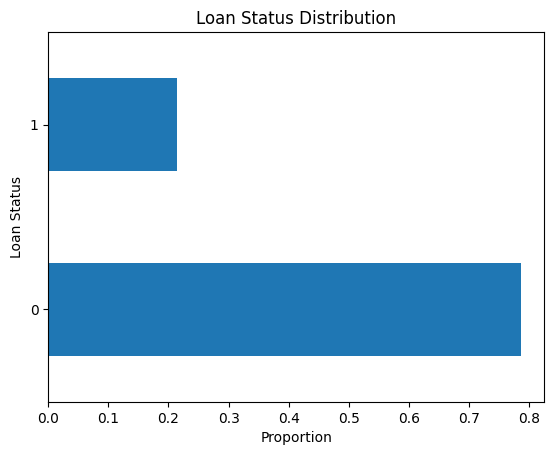

In [12]:
# Understanding the target variable 
df_cleaned['target_default'].value_counts(normalize=True).plot(kind='barh')
plt.title('Loan Status Distribution')
plt.xlabel('Proportion')
plt.ylabel('Loan Status')
#0 means that loan is fully paid, and 1 is otherwise 

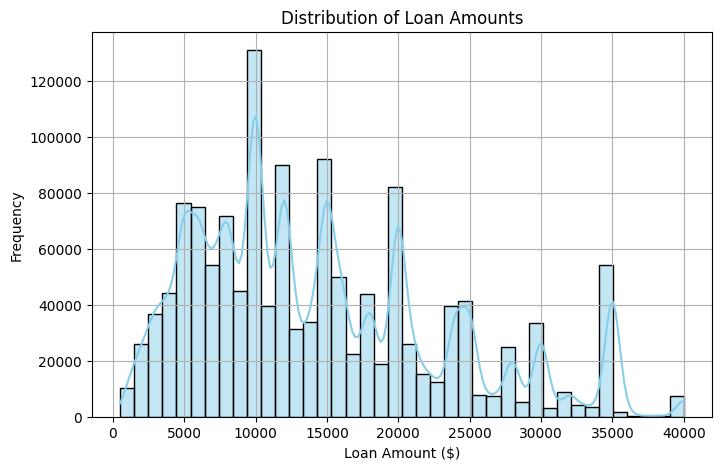

In [13]:
plt.figure(figsize=(8, 5))
sns.histplot(df_cleaned['loan_amnt'], kde=True, bins=40, color='skyblue')
plt.title('Distribution of Loan Amounts')
plt.xlabel('Loan Amount ($)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

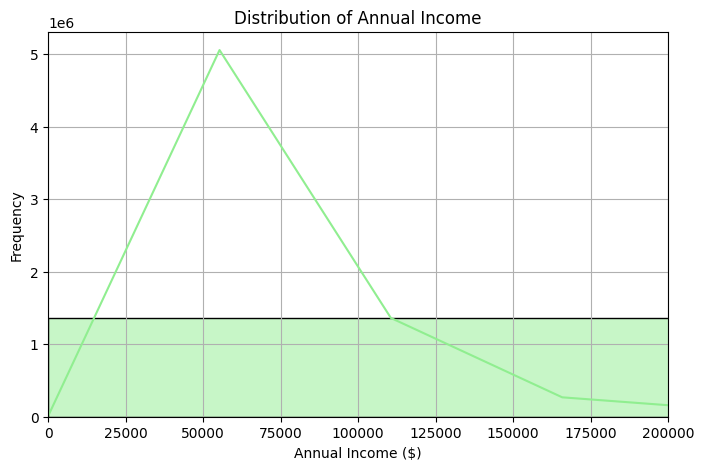

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(df_cleaned['annual_inc'], kde=True, bins=40, color='lightgreen')
plt.title('Distribution of Annual Income')
plt.xlabel('Annual Income ($)')
plt.ylabel('Frequency')
plt.xlim(0, 200000)  # Clip for better visibility
plt.grid(True)
plt.show()

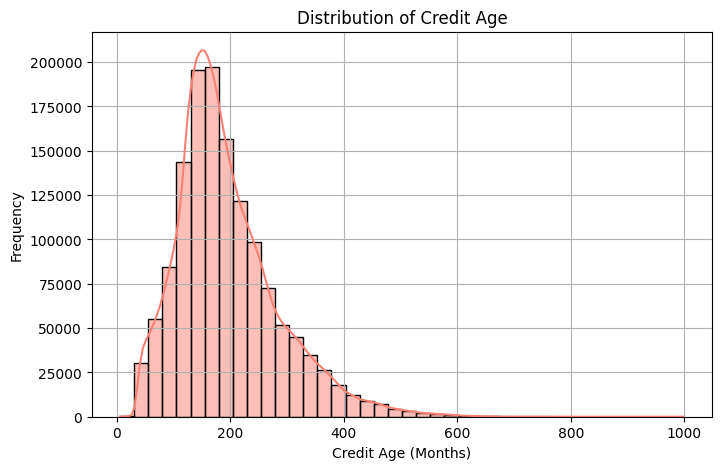

In [15]:
plt.figure(figsize=(8, 5))
sns.histplot(df_cleaned['credit_age (months)'], kde=True, bins=40, color='salmon')
plt.title('Distribution of Credit Age')
plt.xlabel('Credit Age (Months)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

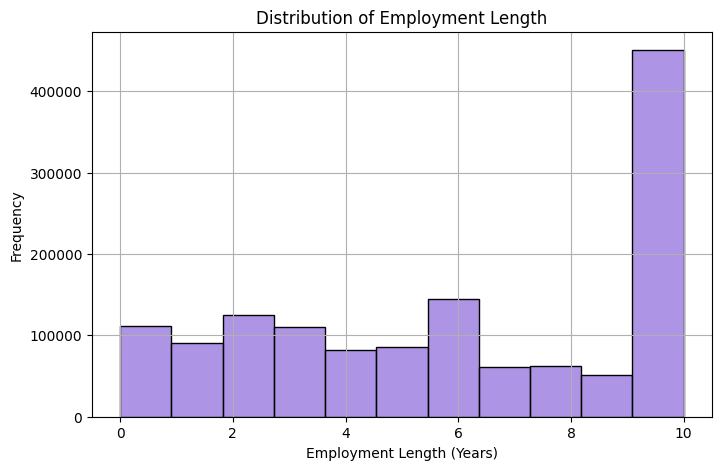

In [16]:
plt.figure(figsize=(8, 5))
sns.histplot(df_cleaned['emp_length'], bins=11, kde=False, color='mediumpurple')
plt.title('Distribution of Employment Length')
plt.xlabel('Employment Length (Years)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

/var/folders/ph/1nkpphrs6tl_n66m_n409by40000gn/T/ipykernel_31207/2759403216.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_cleaned, x='term (months)', palette='Set2')


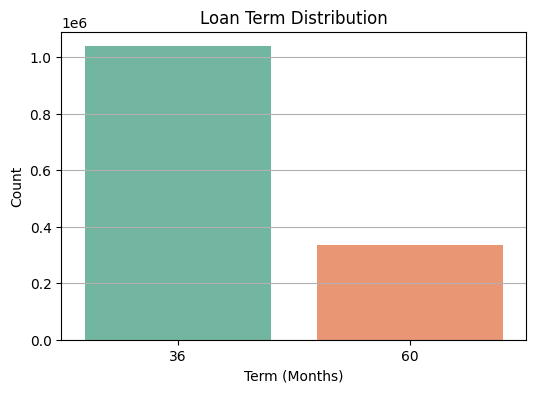

this analysis shows that there are more users choosing the 36 months plan compared to the 60 months plan


In [17]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_cleaned, x='term (months)', palette='Set2')
plt.title('Loan Term Distribution')
plt.xlabel('Term (Months)')
plt.ylabel('Count')
plt.grid(True, axis='y')
plt.show()

print("this analysis shows that there are more users choosing the 36 months plan compared to the 60 months plan")

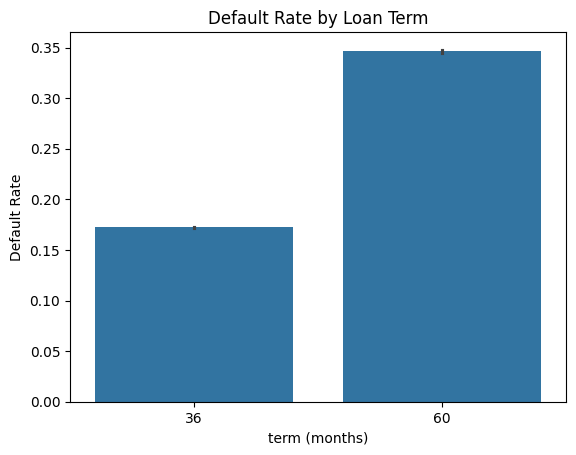

this plot shows that borrowers choosing the 60 months plan are more likely to default, meaning they did not fully repay the loan


In [18]:
#Bivariate analysis 
#loan_status vs term(months)
df_cleaned.groupby('term (months)')['target_default'].value_counts(normalize=True).unstack()
sns.barplot(data=df_cleaned, x='term (months)', y='target_default')
plt.ylabel('Default Rate')
plt.title('Default Rate by Loan Term')
plt.show()

print("this plot shows that borrowers choosing the 60 months plan are more likely to default, meaning they did not fully repay the loan")

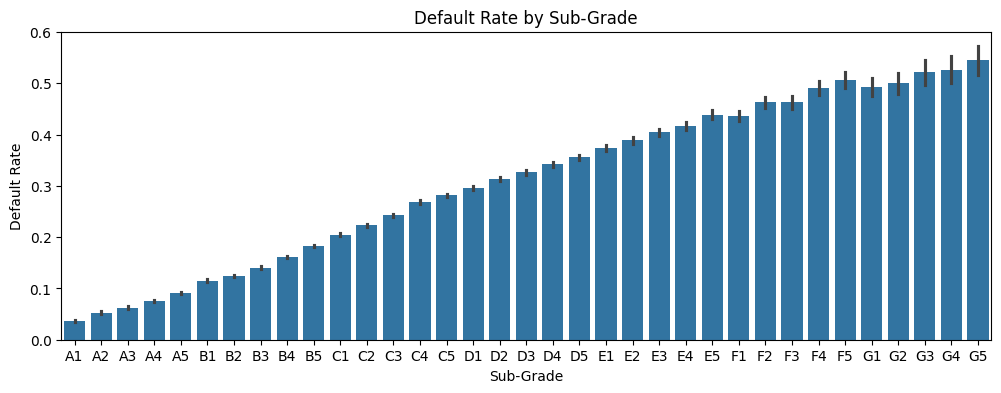

In [19]:
# Default rate vs sub_grade 
plt.figure(figsize=(12,4))
ordered_subgrades = sorted(df_cleaned['sub_grade'].unique())  # You encoded this earlier
sns.barplot(data=df_cleaned, x='sub_grade', y='target_default', order=ordered_subgrades)
plt.title("Default Rate by Sub-Grade")
plt.ylabel("Default Rate")
plt.xlabel("Sub-Grade")
plt.show()

In [20]:
df_cleaned['annual_inc']

0           55000.0
1           65000.0
2           63000.0
4          104433.0
5           34000.0
             ...   
2260688    130000.0
2260690    180792.0
2260691    157000.0
2260692    150000.0
2260697    110000.0
Name: annual_inc, Length: 1373510, dtype: float64

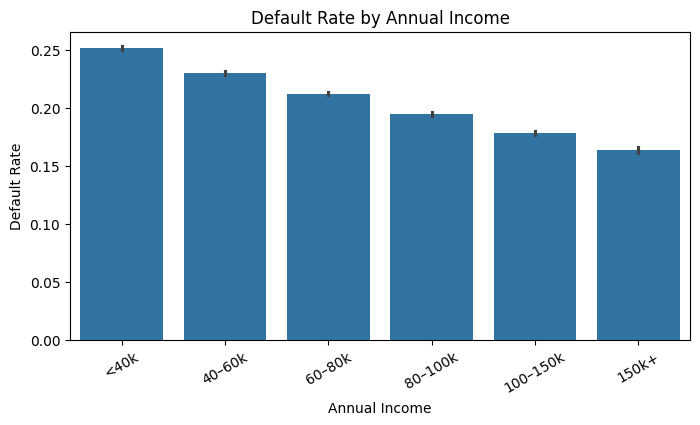

In [21]:
# Default Rate vs. Annual Income 
# the data is binned to reduce noises, binning groups continuous numerical data into discrete intervals 

df_cleaned['income_bin'] = pd.cut(df_cleaned['annual_inc'], bins=[0, 40000, 60000, 80000, 100000, 150000, np.inf],
                                  labels=['<40k', '40–60k', '60–80k', '80–100k', '100–150k', '150k+'])

plt.figure(figsize=(8,4))
sns.barplot(data=df_cleaned, x='income_bin', y='target_default')
plt.title("Default Rate by Annual Income")
plt.ylabel("Default Rate")
plt.xlabel("Annual Income")
plt.xticks(rotation=30)
plt.show()

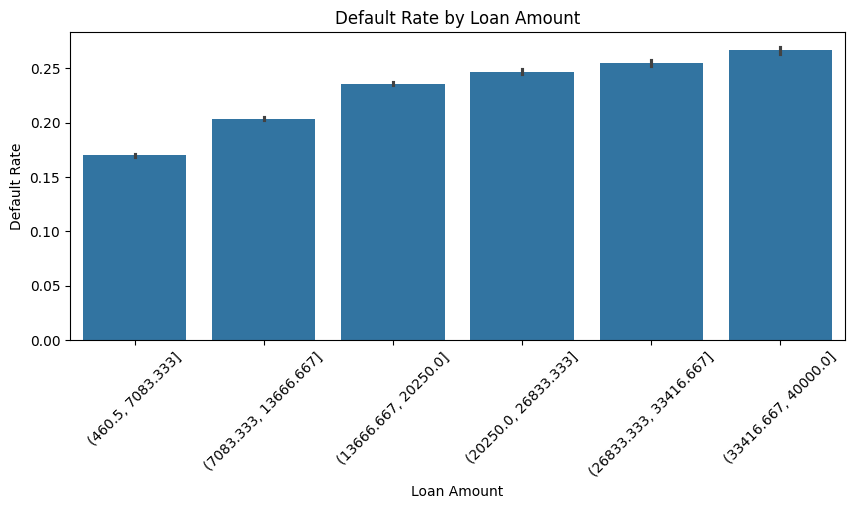

In [22]:
# default rate by loan amount 

df_cleaned['loan_amt_bin'] = pd.cut(df_cleaned['loan_amnt'], bins=6)

plt.figure(figsize=(10,4))
sns.barplot(data=df_cleaned, x='loan_amt_bin', y='target_default')
plt.title("Default Rate by Loan Amount")
plt.ylabel("Default Rate")
plt.xlabel("Loan Amount")
plt.xticks(rotation=45)
plt.show()

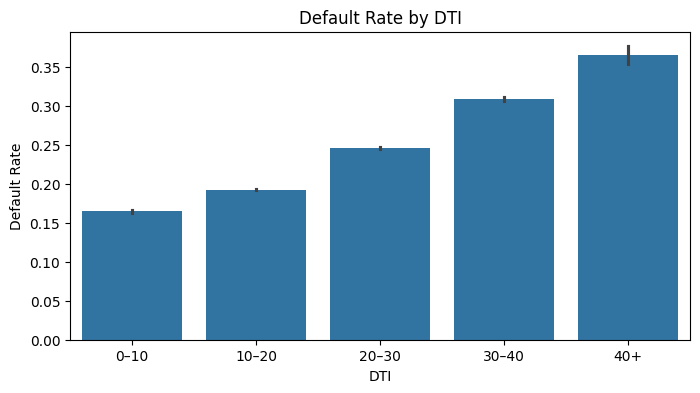

In [23]:
# default rate by DTI (debt to income ratio)

df_cleaned['dti_bin'] = pd.cut(df_cleaned['dti'], bins=[0, 10, 20, 30, 40, np.inf],
                               labels=['0–10', '10–20', '20–30', '30–40', '40+'])

plt.figure(figsize=(8,4))
sns.barplot(data=df_cleaned, x='dti_bin', y='target_default')
plt.title("Default Rate by DTI")
plt.ylabel("Default Rate")
plt.xlabel("DTI")
plt.show()

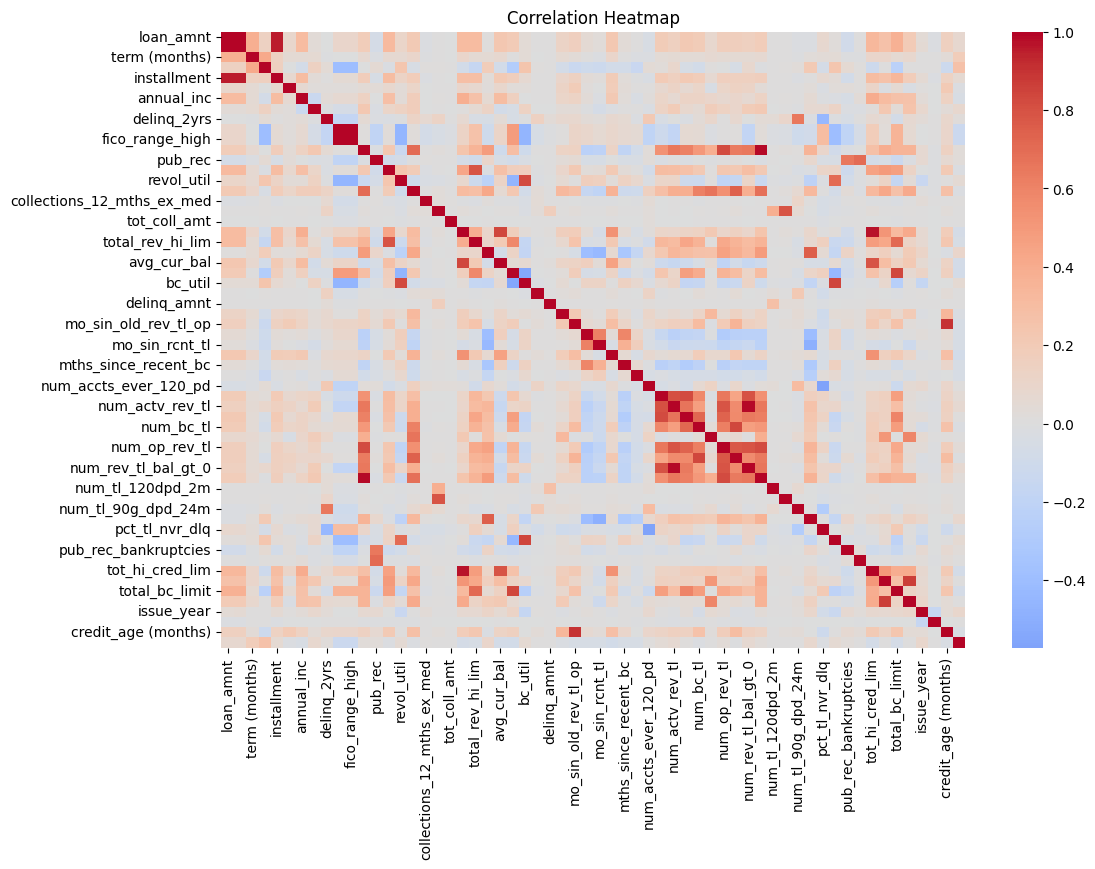

due to a large number of variables, it's difficult to see the exact correlation value, however, we can analyze from the colors which one has a high correlation, simply for insight


In [24]:
plt.figure(figsize=(12,8))
num_cols = df_cleaned.select_dtypes(include='number')
corr = num_cols.corr()
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title("Correlation Heatmap")
plt.show()

print("due to a large number of variables, it's difficult to see the exact correlation value, however, we can analyze from the colors which one has a high correlation, simply for insight")

In [25]:
print("Now, we will find which features have a correlation of 0.85 or greater, as this high value may contribute to redundant information.")

corr_matrix = df_cleaned.select_dtypes(include='number').corr().abs()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Extract pairs with correlation ≥ 0.85
high_corr_pairs = upper.stack().reset_index()
high_corr_pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
high_corr_pairs = high_corr_pairs[high_corr_pairs['Correlation'] >= 0.85].sort_values(by='Correlation', ascending=False)

display(high_corr_pairs)

Now, we will find which features have a correlation of 0.85 or greater, as this high value may contribute to redundant information.


,Feature 1,Feature 2,Correlation
495,fico_range_low,fico_range_high,1.000000
0,loan_amnt,funded_amnt,0.999556
625,open_acc,num_sats,0.983092
1499,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.982007
982,tot_cur_bal,tot_hi_cred_lim,0.973154
61,funded_amnt,installment,0.953680
3,loan_amnt,installment,0.953027
1303,mo_sin_old_rev_tl_op,credit_age (months),0.897736
1750,total_bal_ex_mort,total_il_high_credit_limit,0.870171


In [26]:
#drop redundant features 
redundant_features = [
    'fico_range_high',
    'loan_amnt', 
    'num_actv_rev_tl', 
    'num_sats',
    'mo_sin_old_rev_tl_op',  
    'tot_hi_cred_lim', 
    'income_bin', 'loan_amt_bin', 'dti_bin' #the binned values from previous EDA will also be dropped
    
]

df_cleaned = df_cleaned.drop(columns = redundant_features)

In [27]:
df_cleaned.columns.tolist()

['funded_amnt',
 'term (months)',
 'int_rate',
 'installment',
 'sub_grade',
 'emp_length',
 'annual_inc',
 'dti',
 'delinq_2yrs',
 'fico_range_low',
 'open_acc',
 'pub_rec',
 'revol_bal',
 'revol_util',
 'total_acc',
 'collections_12_mths_ex_med',
 'acc_now_delinq',
 'tot_coll_amt',
 'tot_cur_bal',
 'total_rev_hi_lim',
 'acc_open_past_24mths',
 'avg_cur_bal',
 'bc_open_to_buy',
 'bc_util',
 'chargeoff_within_12_mths',
 'delinq_amnt',
 'mo_sin_old_il_acct',
 'mo_sin_rcnt_rev_tl_op',
 'mo_sin_rcnt_tl',
 'mort_acc',
 'mths_since_recent_bc',
 'mths_since_recent_inq',
 'num_accts_ever_120_pd',
 'num_actv_bc_tl',
 'num_bc_sats',
 'num_bc_tl',
 'num_il_tl',
 'num_op_rev_tl',
 'num_rev_accts',
 'num_rev_tl_bal_gt_0',
 'num_tl_120dpd_2m',
 'num_tl_30dpd',
 'num_tl_90g_dpd_24m',
 'num_tl_op_past_12m',
 'pct_tl_nvr_dlq',
 'percent_bc_gt_75',
 'pub_rec_bankruptcies',
 'tax_liens',
 'total_bal_ex_mort',
 'total_bc_limit',
 'total_il_high_credit_limit',
 'issue_year',
 'issue_month',
 'credit_age (

# Feature selection

In [28]:
cat_cols = ['sub_grade']
df_cleaned = pd.get_dummies(df_cleaned, columns = cat_cols, drop_first = True)

In [29]:
X = df_cleaned.drop(columns=['target_default'])
y = df_cleaned['target_default']

selector = VarianceThreshold(threshold=0.01)
X_reduced = selector.fit_transform(X)  # X is your feature matrix

# Get selected feature names if using pandas DataFrame
selected_features = X.columns[selector.get_support()]

In [30]:
selected_features

Index(['funded_amnt', 'term (months)', 'int_rate', 'installment', 'emp_length',
       'annual_inc', 'dti', 'delinq_2yrs', 'fico_range_low', 'open_acc',
       ...
       'sub_grade_D1', 'sub_grade_D2', 'sub_grade_D3', 'sub_grade_D4',
       'sub_grade_D5', 'sub_grade_E1', 'sub_grade_E2', 'sub_grade_E3',
       'sub_grade_E4', 'sub_grade_E5'],
      dtype='object', length=116)

In [39]:
#use XGBoost filtering for selecting only important features to be used for modelling 

model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model.fit(X_reduced, y)

importances = model.feature_importances_
important_features = X.columns[selector.get_support()][importances > 0.01]  # adjust threshold

important_features = list(important_features)
important_features

/Users/cathelyntan/Documents/smart-credit-risk/venv/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [13:37:02] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


['funded_amnt',
 'term (months)',
 'int_rate',
 'dti',
 'fico_range_low',
 'acc_open_past_24mths',
 'avg_cur_bal',
 'mort_acc',
 'num_rev_tl_bal_gt_0',
 'issue_year',
 'home_ownership_MORTGAGE',
 'home_ownership_RENT',
 'purpose_small_business',
 'addr_state_CO',
 'addr_state_OR',
 'addr_state_WA']

In [42]:
selected = important_features + ['target_default']
df_final = df_cleaned[selected]
df_final.to_csv('../data/cleaned_lendingclub_important_features.csv', index=False)

# Insights summary

## Key Insights

- 60-month loans default about twice as often as 36-month loans.
- Default rates go up a lot for lower credit sub-grades (D to G).
- Borrowers earning under $40k, or with a debt-to-income ratio above 30, are much more likely to default.
- Some columns basically repeat each other (like loan amount and funded amount), so I removed the duplicates to keep things simpler.
